[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manar-c/sscs-ose-code-a-chip.github.io/blob/silk-serdes/ISSCC27/submitted_notebooks/silk_serdes/serdes_demo.ipynb)

# Introducing Silk with a Portable SerDes design example
## Silk is a framework for custom IC design that takes you through the whole flow: specs, sizing, simulation, verification, reports, design history and layout.
### This notebook is a circuit design walkthrough from hierarchy to verified results
### Author:  Manar El-Chammas

**Team: Manar El-Chammas (representative)**

**SSCS Code-a-Chip · ISSCC 2027**

**This notebook introduces Silk and shows how its features work together in a complete circuit-design example.** Silk is a Python framework for custom IC design. We use a SerDes transmitter to demonstrate how a designer can build a circuit, define its specifications, improve its performance, verify changes and preserve the results in one workflow.

Circuit design involves repeated questions: Does this sizing meet the target? Does it still work across process and temperature? What changes when we use another architecture or process? Answering these questions requires the circuit, stimulus, measurements and specifications to stay consistent. **Silk lets designers define that verification once and reuse it as the circuit evolves.** In Silk, a circuit is represented by a Python object that holds its hierarchy, registered testbenches, specifications and optional behavioral model. Its tests can be run directly, its parameters can be swept or optimized, and its results can be saved with the design version and operating conditions that produced them.

Our example is a **600 Mb/s SerDes transmitter with a 10:1 serializer and a four-tap equalizing driver**. We start with a CMOS implementation in sky130 whose baseline eye fails its target. We use Silk to optimize the equalizer, check PVT variation, examine predriver mismatch and device stress, and calibrate a fast behavioral model against transistor simulation. We also estimate area and parasitic loading, compare a CML implementation using the same link test, and demonstrate a GF180MCU preview port with explicit process-specific device and sizing choices.

**Silk also connects specifications to physical design.** The hierarchy, specifications and characterization results remain associated with the circuit as it moves from behavioral modeling through transistor verification toward layout. This helps preserve the intent and information established at earlier stages, so later design decisions can use them. In this demo, we estimate area and parasitic capacitance from the hierarchy, add the estimated capacitance to the circuit, and rerun the link test against the same specifications. That closes an early feedback loop between physical estimates and electrical performance; the notebook demonstrates layout estimation, rather than a completed layout.

These steps show the practical value of Silk: **reusable circuit blocks and tests, automated design exploration, feedback from physical estimates, and preservation of design intent and results across stages.** The saved design history can be reopened without repeating simulations. Because the circuit and its verification are expressed in Python, designers can review and version them, compose them into larger designs, and automate the flow with scripts or AI agents. The walkthrough shows how to apply these capabilities to a real transistor-level example, with measured results and specification checks at each stage.


## 1. Set up the notebook

Run the cell below to install Silk, ngspice and the sky130/GF180 models, or reuse
matching installations. Setup needs an internet connection and several gigabytes
of disk space. Then run the remaining cells in order. Results go to `artifacts/`.

**Run time:** the reported run with all **27 PVT combinations** took **1 h 47 min**, including **65 min for PVT**. The notebook now defaults to **3 grouped PVT points** to shorten the walkthrough; the other stages still run. Set `PVT_GROUPED = False` in section 7.4 for all 27 combinations. Allow additional time for setup and model downloads; runtime depends on the machine.

The embedded figures are saved results from the earlier development reference run. They can be reviewed on GitHub without executing the notebook; the final published-notebook Colab run is still being verified.

[View the setup script](tools/setup_notebook.py) if you want to inspect the installation steps.

Silk is installed from PyPI as `circuitsilk==0.2.0`. In Colab, the first cell downloads the project before running setup. Locally, open the notebook from the complete project folder.


### Recommended reference environment

| Tool or model | Version |
|---|---|
| Python | 3.12 |
| Silk (`circuitsilk`) | 0.2.0 — published on PyPI |
| ngspice | 42 (Ubuntu package `42+ds-3build1`) |
| JupyterLab | 4.6.4 |
| NumPy / Matplotlib | 2.5.3 / 3.11.2 |
| Volare | 0.20.6 |
| PDK variants | sky130A and gf180mcuD (GF180 preview) |

Both PDK libraries use open_pdks revision `c6d73a35f524070e85faff4a6a9eef49553ebc2b`.
The setup script pins pdksetup to revision `703e8eb5d89710026976ec49fd1b9e0785a3f705`.

These are the reference-environment versions. Setup records the versions actually used in `artifacts/environment.json`; the published Silk wheel hash and model pins are in [environment.json](environment.json).

In [ ]:
# In Colab, download the project; locally, use the current project folder.
import sys
import subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("tools/setup_notebook.py").is_file():
    subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none",
                    "--sparse", "-b", "silk-serdes",
                    "https://github.com/manar-c/sscs-ose-code-a-chip.github.io", "code-a-chip"], check=True)
    subprocess.run(["git", "-C", "code-a-chip", "sparse-checkout", "set",
                    "ISSCC27/submitted_notebooks/silk_serdes"], check=True)
    %cd code-a-chip/ISSCC27/submitted_notebooks/silk_serdes

# Refresh the submission files when Colab reuses an earlier checkout.
# Fast-forward only: local edits are preserved, or Git stops with an error.
if "google.colab" in sys.modules:
    subprocess.run(["git", "pull", "--ff-only", "origin", "silk-serdes"], check=True)
    # Drop cached demo imports so subsequent cells use the refreshed files.
    import importlib
    for name in list(sys.modules):
        if name in ("circuits", "characterization", "tools.notebook_display") or name.startswith(("circuits.", "characterization.")):
            del sys.modules[name]
    importlib.invalidate_caches()

# Install Silk from PyPI, check ngspice/PDKs, and record the environment.
%run tools/setup_notebook.py


In [ ]:
# Display figures and save result summaries throughout the walkthrough.
from pathlib import Path
from IPython.display import Image, Markdown, display
from dataclasses import asdict
import json

## 2. Build the reference transmitter

Silk lets a design select different circuit implementations through simple configuration settings. In this SerDes transmitter, `VARIANT` selects `"cmos"` or `"cml"`. Both implementations use the same link testbench, measurements and specifications.

Keep `VARIANT = "cmos"` for the main walkthrough. We will follow this transmitter through the complete design flow before testing the CML implementation in section 10. Both implementations are defined in `circuits/`, adapted from the original Silk examples.

The reference design uses sky130. Silk also includes preview integrations for **GF180MCU** and **IHP SG13G2**. Section 11 demonstrates porting the circuit hierarchy to GF180MCU using explicit device, sizing and supply-voltage mappings, then running the same tests again.


In [ ]:
VARIANT = "cmos"  # Supported choices: "cmos", "cml".
CMOS_PREDRIVER = True  # False reproduces direct FFE loading; CMOS only.
if VARIANT not in {"cmos", "cml"}:
    raise ValueError(f"Unsupported transmitter variant: {VARIANT!r}")

from circuits.transmitter import build_serdes_tx
from silk.circuit.composition import module_graph, save_graph_png

# Building the circuit does not run a simulation.
tx = build_serdes_tx(variant=VARIANT, cmos_predriver=CMOS_PREDRIVER)
# Silk API: read the circuit hierarchy and its connections.
graph = module_graph(tx, depth=1)
print(f"Built {graph['name']} ({VARIANT}, sky130)")
print("Structural construction only; all performance results remain unmeasured.")


### 2.1 Local circuit code

The main notebook imports `circuits.transmitter.build_serdes_tx`. That function composes our local serializer, retiming cells, drivers, and reference channel. The hierarchy remains intact; it is not flattened for the notebook.

| File | Responsibility |
|---|---|
| `circuits/transmitter.py` | Top-level connection of blocks |
| `circuits/serializer.py` | CMOS/CML serializer definitions |
| `circuits/drivers.py` | Driver entry points and CMOS FFE definition |
| `circuits/stdcells.py`, `circuits/cml_cells.py` | Local device-level cell definitions, including the CML FFE driver |
| `circuits/process.py` | Explicit sky130/GF180MCU device, voltage, corner, and sizing mapping |
| `characterization/testbenches.py` | Retained CMOS cell testbench helpers |
| `characterization/stimulus.py` | PRBS9 bits, warmup and serializer word padding |
| `characterization/transmitter.py` | SerDes-specific shared CMOS/CML link testbench and plots; execution uses Silk directly in section 5 |
| `characterization/link_metrics.py` | Training-only PRBS alignment/error checking and native Silk eye measurements |
| `characterization/calibration.py` | Local response fitting and native Silk behavioral model construction |

The circuit definitions are included in this project’s `circuits/` folder and use Silk’s native APIs.

The next cell displays the actual top-level builder so its wiring is visible here without maintaining a duplicate implementation.


In [ ]:
import inspect
from IPython.display import Code
print(f"Local builder: {inspect.getfile(build_serdes_tx)}")
display(Code(inspect.getsource(build_serdes_tx), language="python"))


## 3. Inspect the reusable hierarchy

Silk generates this block diagram from the circuit hierarchy and its connections. The default CMOS signal chain is **parallel data → serializer → retiming and equalization → differential output → channel**.

1. **Serializer (`ser`).** `LOAD` captures ten parallel input bits (`P0`–`P9`). The serializer shifts them out on `sout`, one bit per clock cycle.
2. **Retiming stages (`rt1`–`rt3`).** Three flip-flops provide copies of the serial stream delayed by one, two and three bit periods (unit intervals, or UI). These signals feed the equalizer taps.
3. **Feed-forward equalizer (`driver`).** The driver combines four weighted taps to compensate for channel distortion. The main tap uses `rt1`; the precursor uses `sout`, one bit ahead of the main tap; and the two postcursor taps use `rt2` and `rt3`. The CMOS predrivers inside this block isolate the flip-flops from the output-stage gate load. `inv_soutb` supplies the complementary precursor signal.
4. **Output and channel.** The driver produces `PADP` and `PADN`. The resistor-capacitor channel connects these outputs to `RXP` and `RXN`, where we measure the differential eye and decode the bits. These are observation nodes; this example does not include a receiver circuit.

The CML option keeps the same serializer, tap delays and channel flow, using differential logic and a current-mode driver. Section 5 tests the initial CMOS design; section 7 adjusts the equalizer tap strength.


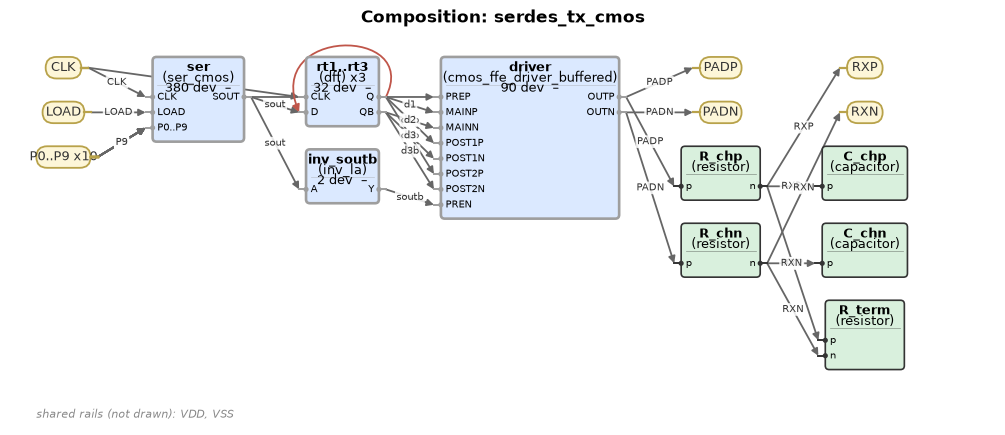

In [ ]:
# Silk API: draw the circuit hierarchy as a block diagram.
figure_path = ARTIFACTS / f"{VARIANT}_hierarchy.png"
save_graph_png(graph, str(figure_path))

# Jupyter: display the saved image in the notebook.
display(Image(filename=str(figure_path)))

## 4. Choose the test conditions and specifications

We start with a **600 Mb/s** link at **1.8 V, 27 °C**, using the typical (`tt`) sky130 process corner. The settings in the next cell define the stimulus, operating conditions and pass/fail targets. We will use these same tests to compare the CMOS and CML implementations.

**Drive the serializer with known data.** A PRBS9 is a repeatable pseudo-random sequence with a period of 511 bits. Silk's `prbs_bits()` generates the sequence, and `sources.voltage.bitpattern()` drives the ten parallel input lanes. The demo arranges the bits into serializer words and chooses which bits to measure.

Choose `run_length="quick"` to measure 128 bits, or `"full"` to measure a complete 511-bit period. Both runs start with 64 warmup bits and end with at least 16 extra bits so the measurement window is clear of startup and the end of the stimulus. The sequence is padded to complete ten-bit words. One unit interval (UI) is one bit period.

Silk also provides a `PRBS` source for a serial input, illustrated below. Native bit sources expose `.stream` to read the emitted bits and `.as_parameters()` to record their settings. Each source holds its first bit before the start delay and its last bit after the sequence ends. For complementary CML inputs, the testbench swaps the high and low voltage levels while keeping the same transition times.

**Set the channel and clock.** Each channel leg contains a 50 Ω series resistor and a 2 pF shunt capacitor. The CMOS receiver also has a 100 Ω differential termination; the CML version uses its driver load resistors without this additional termination. The clock has 50 ps edges and no added jitter. These conditions remain fixed during equalizer optimization.

**Declare what counts as a passing link.** The initial targets are:

- No errors in the measured bits.
- Eye height of at least **100 mV**.
- Eye width of at least **0.4 UI**.

Silk's `eye_diagram()` measures the eye at a 0 V differential threshold and automatically centers the opening. A separate check uses native `sample()` and a voltage threshold to compare the received bits with the transmitted sequence. It chooses latency and sampling phase using warmup data, then holds those choices fixed during measurement. This checks both the eye opening and whether the correct data arrived.

Silk measures eye height, eye width and bit errors from the received waveform. Each measurement is checked against its specification. In section 7, the optimizer uses eye height to select the equalizer setting. Power is also measured, with an optional limit set by `max_power_w`.

**Register the link test.** The cell below calls the demo's [`build_characterization()`](characterization/transmitter.py) function. Inside that function, Silk's `dut.create_test("link", parameters=...)` registers a test named `link` on the transmitter. The function adds the sources, transient analysis, measurements and specifications, then returns the circuit and its testbench as `nominal_dut` and `nominal_tb`. This prepares the test; section 5 executes it with `dut.run_test("link", ...)`.

After nominal optimization, section 7.4 varies process, supply and temperature using Silk's sweep APIs. It can test paired conditions or every combination. One shared supply `Variable` updates the rail, clock, LOAD and data levels together, including the CML voltage offsets.

These targets are illustrative for this example.


In [ ]:
from characterization.transmitter import DEFAULT_SETTINGS, build_characterization
from characterization.stimulus import prbs_stimulus

# Circuit settings: edit the operating conditions and targets here.
experiment = dict(
    DEFAULT_SETTINGS,
    variant=VARIANT,
    cmos_predriver=CMOS_PREDRIVER,
    supply_v=1.8,
    temperature_c=27,
    bit_rate_hz=600e6,
    run_length="quick",
    min_eye_height_v=0.100,
    min_eye_width_ui=0.4,
    max_power_w=None,  # Measure power without imposing a limit.
)

# Demo function: build the transmitter and register its test named "link".
# Inside: Silk's dut.create_test("link", ...) creates the testbench;
# the function then adds sources, measurements and specifications.
# Simulation starts in section 5.
run_dir = REVIEW / "characterization" / VARIANT
nominal_dut, nominal_tb = build_characterization(
    experiment, run_dir, db_path=DATABASE_PATH)
print("Testbench ready. Simulation starts in section 5.")

In [ ]:
from silk import sources

# Silk API: example of a serial PRBS9 voltage waveform.
# The testbench above uses parallel BitPattern sources to drive the serializer.
ui = 1 / experiment["bit_rate_hz"]
serial_reference = sources.PRBS(
    order=9, length=80, v1=0, v2=experiment["supply_v"],
    ui=ui, td=2*ui, tr=0.05*ui, tf=0.05*ui)

# Silk API: inspect the generated bits and the source settings.
print("First 32 bits:", serial_reference.stream[:32])
print("Source settings:", serial_reference.as_parameters())

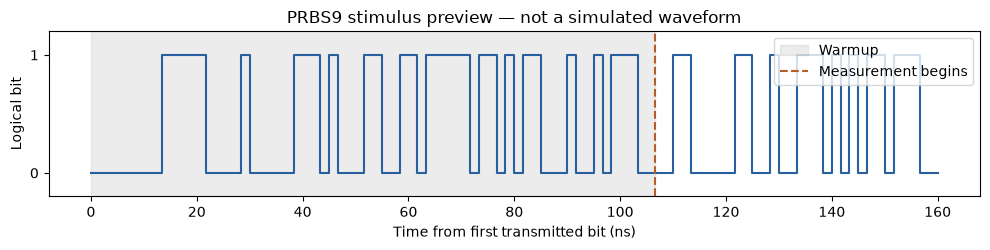

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

stimulus = prbs_stimulus(experiment)
stimulus_bits = np.asarray(stimulus["bits"], dtype=int)
first, stop = stimulus["measurement_bit_range"]
print(f"PRBS9: {len(stimulus_bits)} total bits, {first} warmup, "
      f"{stop-first} measured, {len(stimulus_bits)-stop} trailing/padding.")
print(f"Measurement duration: {stimulus['measurement_duration_s'] * 1e9:.3f} ns")
print(f"Stimulus duration: {stimulus['stimulus_duration_s'] * 1e9:.3f} ns per point")
print("Bit indices refer to the transmitted sequence; receiver alignment comes in section 5.")

preview_count = min(96, len(stimulus_bits))
time_ns = np.arange(preview_count + 1) / experiment["bit_rate_hz"] * 1e9
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.step(time_ns, np.r_[stimulus_bits[:preview_count], stimulus_bits[preview_count-1]],
        where="post", color="#285f9e")
ax.axvspan(0, first / experiment["bit_rate_hz"] * 1e9, alpha=0.15, color="gray", label="Warmup")
ax.axvline(first / experiment["bit_rate_hz"] * 1e9, color="#b55c28", linestyle="--", label="Measurement begins")
ax.set(xlabel="Time from first transmitted bit (ns)", ylabel="Logical bit",
       yticks=[0, 1], ylim=(-0.2, 1.2), title="PRBS9 stimulus preview — not a simulated waveform")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(ARTIFACTS / f"{VARIANT}_prbs9_stimulus.png", dpi=140)
display(fig)
plt.close(fig)

## 5. Simulate and check the transmitter

Next, we run the `link` test registered in section 4 at **1.8 V, 27 °C, tt**. Silk runs ngspice, measures the waveforms, and checks the link specifications. The report includes eye height, eye width, decoded errors, power, and energy per bit.

The decoder uses startup bits 32–63 to choose a sampling delay and phase, then holds them fixed for the measured bits. This models a differential sampler with a 0 V threshold; there is no receiver or clock-recovery circuit. Silk centers the eye display separately, so a good-looking eye does not replace the bit check.

Power includes the transmitter and channel load supplied by VDD. It excludes the ideal clock, LOAD, and data sources. Energy per bit is average power divided by bit rate.

With the default CMOS settings, the baseline fails the eye-height specification: the saved reference run measures **57 mV against the 100 mV target**, despite decoding all measured bits correctly. Section 7 optimizes the auxiliary taps using the same test and specifications, increasing eye height to **862 mV** and meeting the target. `RUN_SPICE = False` allows you to inspect the circuit and stimulus without running simulations.

**Why the CMOS predriver?** Driving the FFE gates directly overloaded the retiming flip-flops. An isolated loaded test produced 35 errors in 64 bits; adding four inverter stages (multipliers 1, 4, 16, 64) reduced this to zero at both tested setup offsets. `CMOS_PREDRIVER = True` enables these buffers.

The testbench limits the output and internal transient steps to the smaller of 0.01 UI and the clock edge time. Each run saves its waveforms, simulator log, settings, and reports.

**Why can a poor eye still have no bit errors?** The decoder only checks whether each sampled differential voltage has the correct sign. A narrow eye can pass that check while failing the eye-height target. This short test has no added noise or clock jitter: zero observed errors is not a zero-BER guarantee. Section 7.1 shows the eye before and after tap optimization.

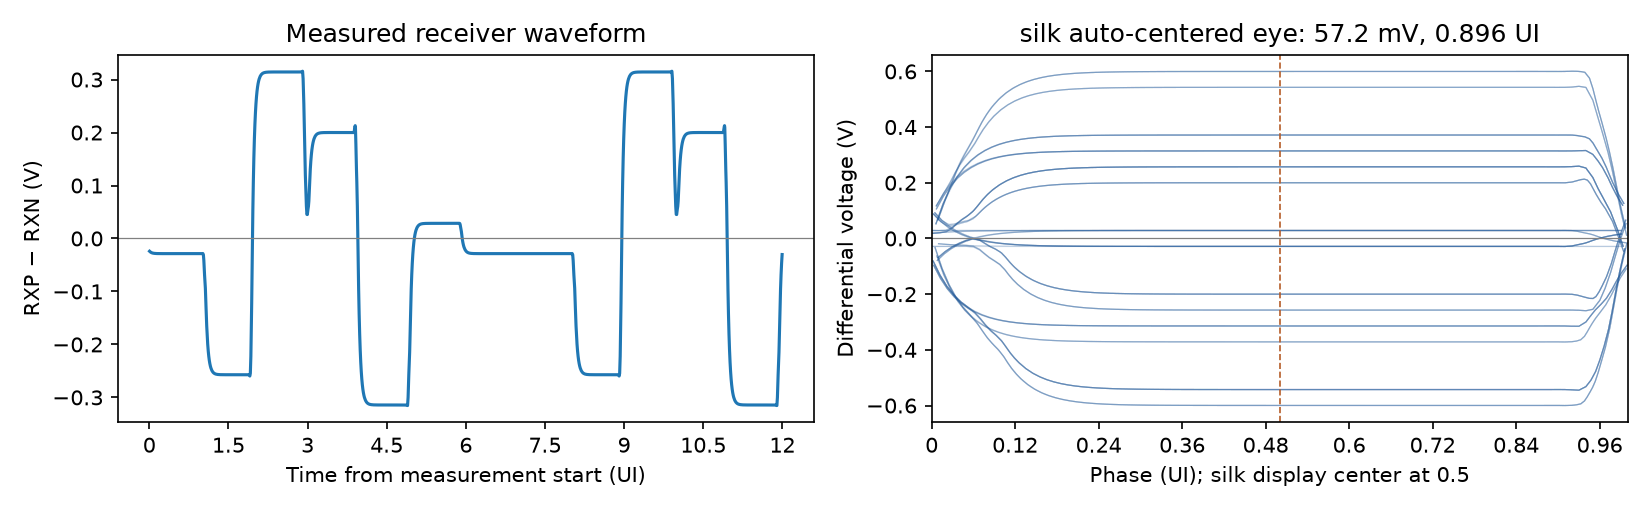

In [ ]:
from silk.circuit.report import generate_report
# Local helpers define THIS circuit's testbench and static figure formatting.
from characterization.transmitter import build_characterization, read_measurements, save_figures

RUN_SPICE = True
characterization_runs = []
if not RUN_SPICE:
    print("SPICE disabled: no section 5 measurements were generated in this execution.")
else:
    settings, dut, tb = experiment, nominal_dut, nominal_tb
    supply_v, temperature_c = settings["supply_v"], settings["temperature_c"]
    # Silk API: set the operating conditions, run the link test, and report.
    tb.set_temperature(temperature_c)
    tb.set_supply_voltage(supply_v, source="vdd")
    print(f"Running {settings['variant'].upper()}: {supply_v:g} V, {temperature_c:g} °C, "
          f"{settings['bit_rate_hz']/1e6:g} Mb/s", flush=True)
    # Silk API: save this circuit version and its measured results in the database.
    dut.create_circuit_version("Original CMOS/CML equalization baseline")
    report = dut.run_test("link", corner="tt", run_label="baseline", store=True)
    print("Database receipt:", report.storage)
    print(report.summary())
    circuit_report = generate_report(tb.netlist, spec_reports=[report])

    circuit_report.save_json(str(run_dir / "report.json"))
    circuit_report.save_html(str(run_dir / "report.html"))
    # Save all measured values, specifications and run conditions with Silk.
    report.save_json(run_dir / "spec_report.json")

    # Save circuit-specific stimulus alongside silk's report and raw data.
    (run_dir / "experiment.json").write_text(
        json.dumps({"settings": settings, "stimulus": prbs_stimulus(settings)}, indent=2, default=asdict) + "\n")
    print(f"Average VDD power: {report.metrics['average_power_w']*1e3:.3f} mW; "
          f"energy: {report.metrics['energy_per_bit_j']*1e12:.3f} pJ/bit")
    if report.metrics["link.training_bit_errors"]:
        print("Training did not decode cleanly: alignment is provisional; "
              "mismatches are diagnostic, not a BER estimate.")
    print(f"Raw waveform: {report.rawfile_path}")
    print(f"Reports: {run_dir}")
    # Demo helpers: collect the measurements and draw a static waveform/eye figure.
    measurements = read_measurements(tb.netlist, settings)
    save_figures(tb.netlist, settings, measurements, run_dir)
    display(Image(filename=str(run_dir / "waveform_eye.png")))
    characterization_runs.append((dut, tb, report, run_dir))


## 6. Inspect the waveforms

Silk's interactive waveform viewer allows you to zoom into the receiver, clock, serializer, and retiming signals. Compare transitions and settling with the eye and bit-error results above.

`emit_view()` creates a standalone HTML viewer. The demo's `show_viewer()` helper only embeds that file in Jupyter. If it does not appear, trust the notebook or open the HTML link below.

The following sections continue with CMOS. Section 10 runs the CML architecture through the same link test.

In [ ]:
# Demo helpers: table formatting and embedding the Silk viewer in Jupyter.
from tools.notebook_display import table, show_viewer, show_file
from silk.signals.view import emit_view
from dataclasses import replace, asdict
import numpy as np
import matplotlib.pyplot as plt

RUN_FULL_FLOW = RUN_SPICE and VARIANT == "cmos"
result_rows = []
run_evidence = []
for index, (_, _, baseline, folder) in enumerate(characterization_runs):
    settings_record=json.loads((folder / "experiment.json").read_text())["settings"]
    label=f"{settings_record['variant'].upper()} baseline {index+1}"
    result_rows.append({"case":label,**{k: v for k, v in baseline.metrics.items() if k != "link"}})
    run_evidence.append({"case":label,"settings":settings_record,"rawfile": baseline.rawfile_path, "parameters": baseline.parameters})

if characterization_runs:
    baseline_dut, baseline_tb, baseline_report, baseline_dir = characterization_runs[0]
    baseline_version = baseline_dut.create_circuit_version()
    view_path = REVIEW / "baseline_waveforms.html"
    # Silk API: generate an interactive viewer from the simulated waveforms.
    emit_view(baseline_report.rawfile_path, str(view_path), inline=True,
              signals=(["v(rxp)","v(rxn)","v(clk)","v(xdut.sout)","v(xdut.d1)","v(xdut.d2)","v(xdut.d3)"]
                       if VARIANT == "cmos" else ["v(rxp)","v(rxn)","v(clkp)","v(clkn)"]),
              title="SerDes: real transistor waveforms",
              commands=[{"cmd":"addSignal","args":{"panel":0,"signals":["v(rxp)","v(rxn)"]}}])
    # Jupyter display only; the viewer itself was generated by Silk.
    show_viewer(view_path)
    show_file(view_path.relative_to(DEMO_ROOT))
else:
    print("SPICE disabled; no measured waveform is shown.")

## 7. Optimize, calibrate, and validate

### 7.1 Choose the auxiliary tap strength

This TX has equalization options, that can compensate channel loss.  `eq_strength` scales the three auxiliary taps while leaving the main tap fixed. Each auxiliary resistance becomes `R / eq_strength`: a value of `0.1` makes those resistors ten times larger. Transistor sizes, tap signs, channel, bit rate, and operating conditions stay fixed.

Silk's built-in `Optimizer` tries **1.0, 0.3, 0.1, and 0.01**. It selects the largest eye height among candidates that meet the link specifications: zero decoded errors, at least 100 mV eye height, and 0.4 UI eye width. Power is measured; a power limit applies only if one was set in section 4.

The code below rerun the best setting and compare it with the baseline.  Both plots use Silk's `eye_diagram(auto_center=True)`; centering changes the display, not the waveform or bit-error result.

In [ ]:
from tools.notebook_display import draw_eye  # Plot formatting only.
from silk import Variable
from matplotlib.ticker import FuncFormatter
from silk.metrics import eye_diagram
from silk.optimize import VariableSpace, Optimizer

optimization_records = []
if RUN_FULL_FLOW:
    # Silk API: define the available trim settings and optimization objective.
    eq = Variable("eq_strength", value=1.0, var_type="categorical",
                  categories=[1.0, 0.3, 0.1, 0.01])
    opt_dut, opt_tb = build_characterization(experiment, REVIEW / "optimization", eq_strength=eq)
    optimizer = Optimizer(opt_tb, VariableSpace([eq]))
    optimizer.add_objective("link.eye_height_v", maximize=True)
    # Silk API: simulate each setting and evaluate the registered specifications.
    print("Running four equalizer settings; this may take several minutes.", flush=True)
    optimization_records = optimizer.sweep(n=4, method="grid", corner="tt", n_workers=1)
    if any(row["status"] != "success" for row in optimization_records):
        raise RuntimeError(optimization_records)
    if optimizer.best is None:
        raise RuntimeError("No candidate meets the declared link specifications; inspect optimization history.")
    selected = dict(experiment, eq_strength=optimizer.best["params"]["eq_strength"])
    selected_dut, selected_tb = build_characterization(selected, REVIEW / "selected", db_path=DATABASE_PATH)
    selected_version = selected_dut.create_circuit_version(
        "Selected equalization after nominal sweep", parent_version_id=baseline_version)
    selected_report = selected_dut.run_test("link", corner="tt", store=True)
    print("Selected version:", selected_version, "parent:", baseline_version)
    print(selected_report.summary())
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
    for ax, title, bench, cfg in [
        (axes[0], "Original tap settings", baseline_tb, experiment),
        (axes[1], f"Selected strength {selected['eq_strength']:g}", selected_tb, selected),
    ]:
        measured = read_measurements(bench.netlist, cfg)
        rx = (bench.probe("rxp") - bench.probe("rxn")).window(
            measured["measurement_start_s"], measured["measurement_stop_s"])
        ui = 1 / cfg["bit_rate_hz"]
        # Silk API: measure and center the differential eye.
        eye = eye_diagram(rx, period=ui, auto_center=True, threshold=0.0)
        # Demo helper: draw the traces and label axes using this Silk result.
        draw_eye(ax, eye, ui, title)
        # Reuse the one native eye result for every displayed field.
        print(title, "silk eye height (V):", eye.height,
              "width (UI):", eye.width/ui,
              "decoded errors:", measured["bit_errors"])
    fig.tight_layout()
    fig.savefig(REVIEW / "optimization_eyes.png", dpi=150)
    plt.close(fig)
    table([{"EQ strength":row["params"]["eq_strength"],"feasible":row["feasible"],
            "eye mV":round(row["metrics"]["link.eye_height_v"]*1e3,2),
            "eye UI":round(row["metrics"]["link.eye_width_ui"],2),
            "power mW":round(row["metrics"]["average_power_w"]*1e3,3)} for row in optimization_records])
    (REVIEW / "optimization.json").write_text(json.dumps({"history":optimization_records,"summary":optimizer.summary(), "artifacts":str(REVIEW / "optimization")},indent=2, default=asdict))
    # Silk API: create one report and save both formats.
    selected_circuit_report = generate_report(selected_tb.netlist, spec_reports=[selected_report])
    selected_circuit_report.save_html(str(REVIEW / "selected_report.html"))
    selected_circuit_report.save_json(str(REVIEW / "selected_report.json"))
    for record in optimization_records:
        result_rows.append({"case":f"CMOS EQ {record['params']['eq_strength']:g}",**{k: v for k, v in record["metrics"].items() if k != "link"}})
    result_rows.append({"case":"CMOS selected",**{k: v for k, v in selected_report.metrics.items() if k != "link"}})
    run_evidence.append({"case":"CMOS selected","settings":dict(selected),"rawfile": selected_report.rawfile_path, "parameters": selected_report.parameters})
else:
    print("Full CMOS flow disabled.")

#### Compare the eye before and after optimization

The left plot uses the original tap settings; the right uses the selected tap strength. Both use the same voltage scale and Silk's auto-centered eye measurement. Compare the vertical opening, not just whether the bits decoded correctly.

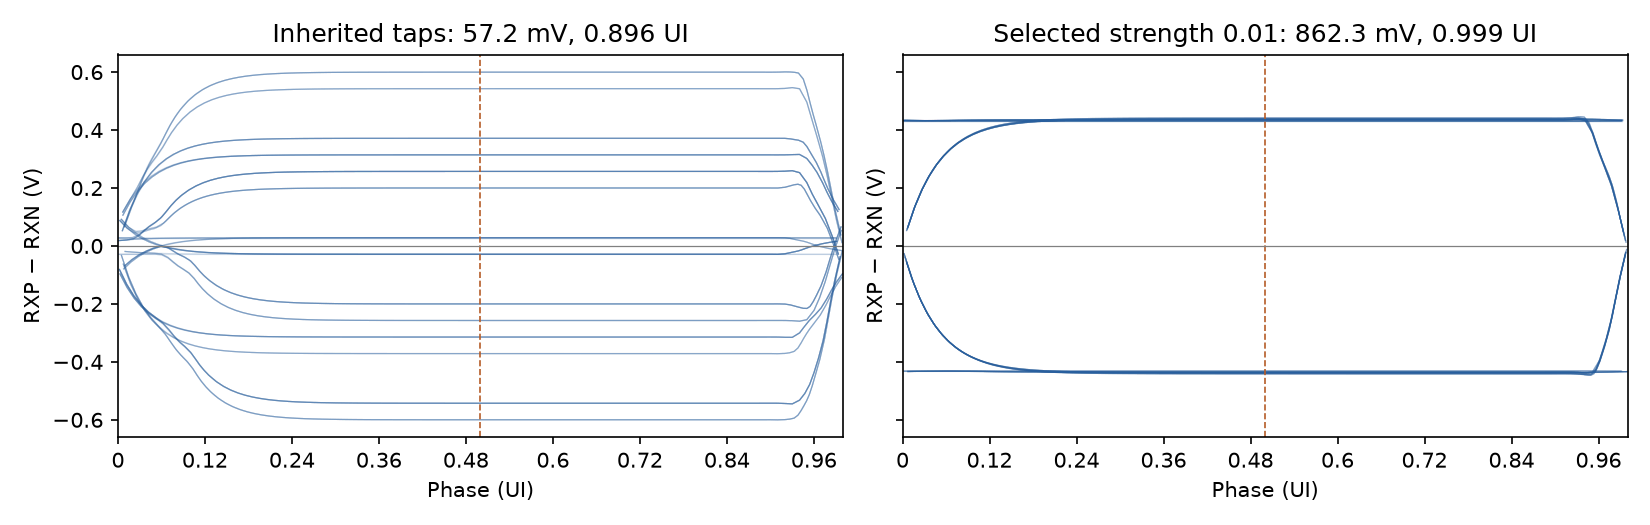

In [ ]:
# Jupyter: show the before/after figure saved by the optimization above.
if RUN_FULL_FLOW:
    display(Image(filename=str(REVIEW / "optimization_eyes.png")))

### 7.2 Calibrate a fast behavioral model

In design, behavioral models are important in verifying functionality without the penalty of spice simulations.  Silk allows an embedded behavioral model to go with the circuit object, and also includes APIs that can calibrate (or fit) different parameters to spice simulations.  In this example, we fit a linear response model to the selected SPICE run. The model uses six bits of history and 21 samples per bit interval to represent the transmitter and channel. The local `fit_response()` helper performs this circuit-specific fit using output intervals 64–191.

Silk's `Measurement` records each fitted coefficient. `CalibrationBinding` connects it to a model parameter, and `reconcile_specs()` applies the measurements to the model. 

The calibrated behavioral model runs without ngspice. 

In [ ]:
from silk.specs import CalibrationBinding, Measurement
from characterization.calibration import (fit_response, build_response_model,
    build_behavioral_bench, validation_residual)

if RUN_FULL_FLOW:
    vp, vn = selected_tb.probe("rxp"), selected_tb.probe("rxn")
    # Demo helper: fit this link model to the SPICE waveform.
    calibration = fit_response(vp.x, (vp - vn).y, selected)
    calibration["training_rawfile"] = selected_report.rawfile_path
    model = build_response_model(selected, REVIEW / "behavioral_model")
    # Silk API: record each coefficient and bind it to a model parameter.
    for name, value in calibration["coefficients"].items():
        spec = model.declare_spec(name=name, metric=name, op="==", target=value,
                                 calibration=CalibrationBinding(target_module=model, param_name=name))
        spec.record_measurement(Measurement(source="spice",value=value,corner="tt",
            temperature=selected["temperature_c"],voltage=selected["supply_v"],
            sim_type="tran",tool_name="ngspice",notes=selected_report.rawfile_path))
    # Silk API: apply the measured coefficients to the behavioral model.
    model.reconcile_specs(prefer_source="spice")
    (REVIEW / "calibration.json").write_text(json.dumps(calibration,indent=2, default=asdict))
    print(f"Calibrated {len(calibration['coefficients'])} scalar response coefficients through silk.")
    print(f"Training fit RMS residual: {calibration['training_rmse_v']*1e3:.3f} mV")

### 7.3 Check model fidelity over a full PRBS9 period

The model was calibrated using only **128 bits**. Now keep the selected tap strength and model coefficients fixed and compare the model with SPICE over **all 511 bits of a PRBS9 period**. This illustrates how well the fitted model reproduces the link response over the complete pattern.

The sequence starts 233 bits later, but it is still the same PRBS9 sequence. The full period includes the training patterns, so this is a full-period fidelity check, not an independent data set. The model is not refitted.

The loop runs three checks at `tt`: the full-period nominal record, 1.7 V / 85 °C, and 1.9 V / −40 °C. The last two use the quick record; the model comparison uses the full-period nominal run.

In [ ]:
validation_runs = []
if RUN_FULL_FLOW:
    validation_cases = [
        ('independent_prbs', dict(selected,prbs_offset=233,run_length="full")),
        ('low_hot', dict(selected,supply_v=1.7,temperature_c=85,prbs_offset=233)),
        ('high_cold', dict(selected,supply_v=1.9,temperature_c=-40,prbs_offset=233)),
    ]
    for label, settings in validation_cases:
        folder = REVIEW / label
        # Demo helper: build the circuit with these operating conditions.
        dut, tb = build_characterization(settings, folder)
        # Silk API: reuse the registered link test and specifications.
        report = dut.run_test("link", corner="tt")
        print(label, report.summary())
        circuit_report = generate_report(dut, spec_reports=[report])
        circuit_report.save_json(str(folder / "report.json"))
        circuit_report.save_html(str(folder / "report.html"))
        validation_runs.append((label,settings,dut,tb,report,folder))
        result_rows.append({"case":label,**{k: v for k, v in report.metrics.items() if k != "link"}})
        run_evidence.append({"case":label,"settings":dict(settings),"rawfile": report.rawfile_path, "parameters": report.parameters})

#### Compare the behavioral model with nominal SPICE

Run the calibrated model on the validation sequence without refitting. Compare its waveform and link specifications with the full-period nominal SPICE run. The local `validation_residual()` helper uses Silk's `error_norm` to report time-weighted RMS and maximum absolute voltage error.

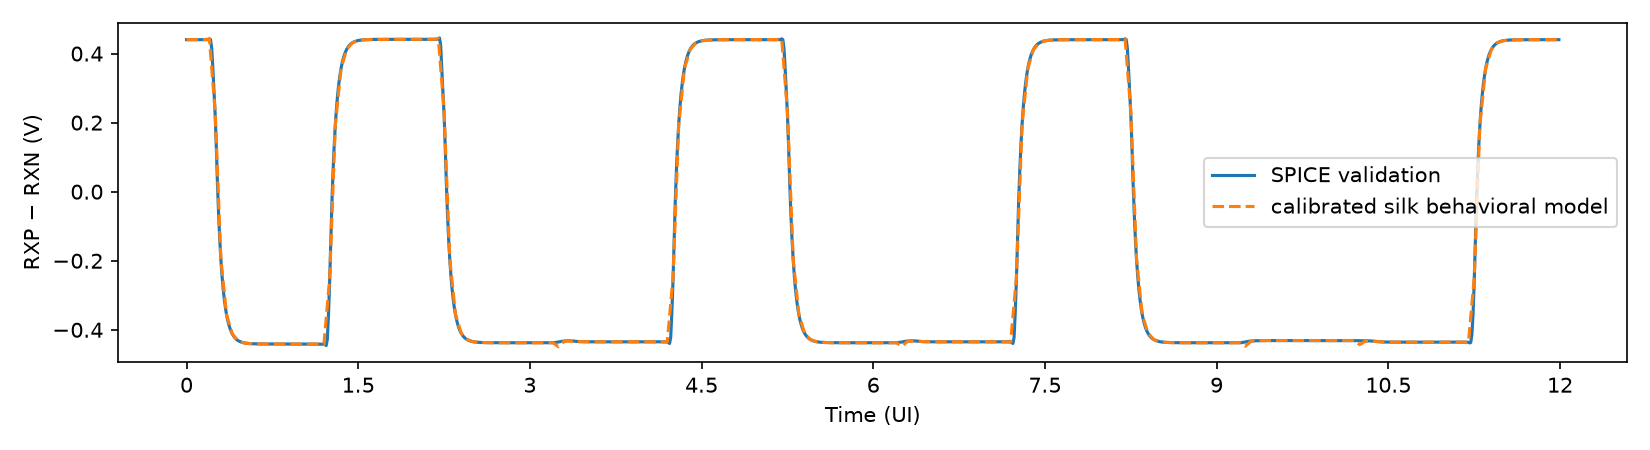

In [ ]:
if RUN_FULL_FLOW:
    _, validation_settings, _, validation_tb, validation_report, _ = validation_runs[0]
    behavioral = build_behavioral_bench(model,validation_settings,REVIEW / "behavioral_validation")
    ui = 1 / validation_settings["bit_rate_hz"]
    # Silk API: declare the output probe, then run the behavioral test.
    prediction = behavioral.probe("dout")
    behavioral_report = behavioral.run()
    print(behavioral_report.summary())
    behavioral_report.save_json(REVIEW / "behavioral_spec_report.json")
    vp,vn = validation_tb.probe("rxp"),validation_tb.probe("rxn")
    residual = validation_residual(prediction.x,prediction.y,vp.x,(vp - vn).y,validation_settings)
    behavioral_metrics = behavioral_report.metrics
    print("Independent validation residual:",residual)
    print("Behavioral link metrics:",behavioral_metrics)
    (REVIEW / "behavioral_validation.json").write_text(json.dumps({"residual":residual,
        "behavioral_metrics":behavioral_metrics,"spice_metrics":{k: v for k, v in validation_report.metrics.items() if k != "link"},
        "validation_settings":dict(validation_settings),"calibration":"calibration.json"},indent=2, default=asdict))
    start = 120*ui
    # Silk API: select and align a short waveform segment for comparison.
    prediction_view = prediction.window(start, start+12*ui)
    reference_view = (vp - vn).interpolate(prediction_view.x)
    fig,ax=plt.subplots(figsize=(11,3))
    reference_view.shift(start).plot(ax=ax, label="SPICE validation")
    prediction_view.shift(start).plot(ax=ax, linestyle="--", label="calibrated silk behavioral model")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda seconds, _: f"{seconds/ui:g}"))
    ax.set(xlabel="Time (UI)",ylabel="RXP − RXN (V)");ax.legend();fig.tight_layout()
    fig.savefig(REVIEW / "behavioral_validation.png",dpi=150);display(Image(filename=str(REVIEW / "behavioral_validation.png")));plt.close(fig)

### 7.4 Check process, voltage, and temperature

Silk enables parametric sweeps. For a shorter walkthrough, the default is **three grouped PVT points**, using the same link test and specifications.

A shared Silk `Variable` sets VDD and the clock, LOAD, and data levels. `set_variable_values()` sweeps it along with `set_corners()` and `set_temperatures()`.

With `PVT_GROUPED = True`, Silk's `set_groups()` pairs the lists: **ss / 1.7 V / 85 °C**, **tt / 1.8 V / 27 °C**, and **ff / 1.9 V / −40 °C**. To run **all 27 combinations**, set `PVT_GROUPED = False` before running the cell below. This crosses three process corners, three temperatures and three supplies.

The worst result is the worst **among the tested points**. The grouped plan does not establish the worst case across all 27 combinations.

The native results table includes failed simulations. `worst()` locates the smallest eye, and `probe.point()` selects that run's waveform. Each successful report is also stored in the database with its captured supply Variable for the later save-and-revisit step.

**Reading the PVT report.** The link results show the measured eye, bit errors and power at each operating point. The report also includes a device-stress section, which shows `no_waveform` here: this combined report is built from the circuit definition, while the waveforms belong to the individual testbench runs. It does not evaluate device stress across the PVT sweep. These entries mean **not checked**, not a stress pass or a voltage-limit violation. Section 8 checks device stress separately on the selected design and its additional validation runs using their saved waveforms.


In [ ]:
from silk import Variable

PVT_GROUPED = True  # True: pair the lists (3 runs); False: cross them (27 runs).
process_evidence = None
if RUN_FULL_FLOW:
    pvt_vdd = Variable("link_vdd", value=1.8, bounds=(1.7, 1.9))
    process_dut, process_tb = build_characterization(
        dict(selected, supply_v=1.8, temperature_c=27), REVIEW / "pvt",
        db_path=DATABASE_PATH, supply_voltage=pvt_vdd, test_name="link_pvt")
    assert process_dut.create_circuit_version(parent_version_id=baseline_version) == selected_version
    # Silk API: declare the run lists and choose paired or crossed conditions.
    process_tb.set_corners(["ss", "tt", "ff"])
    process_tb.set_temperatures([85, 27, -40])
    process_tb.set_variable_values(pvt_vdd, [1.7, 1.8, 1.9])
    process_tb.set_groups([["corner", "temperature", pvt_vdd]] if PVT_GROUPED else None)
    try:
        # Silk API: execute the complete run plan.
        print(f"Running {3 if PVT_GROUPED else 27} PVT points; this may take several minutes.", flush=True)
        process_results = process_tb.run()
        assert pvt_vdd.value == 1.8
        # Silk API: save the complete results table and combined report.
        process_results.to_csv(REVIEW / "pvt_results.csv")
        pvt_report = generate_report(process_dut, test_results=process_results)
        pvt_report.save_json(str(REVIEW / "pvt_report.json"))
        pvt_report.save_html(str(REVIEW / "pvt_report.html"))
        # Silk API: store each report with the Variable values used for that run.
        for report in process_results.reports.values():
            process_dut.store_report(report)
        if process_results.reports:
            worst = process_results.worst("link.eye_height_v")
            print("Worst eye height:", worst)
            print("Worst eye width:", process_results.worst("link.eye_width_ui"))
            print("Maximum power (W):", process_results.stat("average_power_w", "max"))
        process_evidence = {"summary": process_results.summary(),
            "rows": process_results.table(), "grouped": PVT_GROUPED,
            "failed": {str(k): str(v) for k, v in process_results.failed.items()},
            "rawfiles": {str(k): r.rawfile_path for k, r in process_results.reports.items()},
            "version_id": selected_version, "restored_supply_variable_v": pvt_vdd.value}
        (REVIEW / "pvt_results.json").write_text(json.dumps(process_evidence, indent=2, default=asdict))
    finally:
        process_dut.close()
        process_tb.netlist.close()
else:
    print("PVT simulations disabled.")


In [ ]:
# Show the PVT report separately from simulation progress messages.
if process_evidence is not None:
    display(Markdown("**PVT report — all operating points and specification results**\n\nIn Colab, download the HTML report and open it in your browser."))
    show_file((REVIEW / "pvt_report.html").relative_to(DEMO_ROOT))
    print(process_evidence["summary"])
    display(Markdown("**Download the results table**"))
    show_file((REVIEW / "pvt_results.csv").relative_to(DEMO_ROOT))

In [ ]:
# Compare typical conditions with the tested point having the narrowest eye.
# These are saved waveforms: this cell does not run another simulation.
if RUN_FULL_FLOW and process_results.reports:
    worst_width = process_results.worst("link.eye_width_ui")
    worst_report = process_results.reports[worst_width.corner]
    # Silk API: select the differential waveform at this run-plan point.
    worst_rx = (process_tb.probe("rxp") - process_tb.probe("rxn")).point(worst_width.corner)
    typical_rx = selected_tb.probe("rxp") - selected_tb.probe("rxn")
    ui = 1 / selected["bit_rate_hz"]
    first, stop = prbs_stimulus(selected)["measurement_bit_range"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
    for ax, title, rx, report in [
        (axes[0], "Typical: tt, 27 °C, 1.8 V", typical_rx, selected_report),
        (axes[1], "Worst tested eye width", worst_rx, worst_report),
    ]:
        # Reuse the alignment recorded by the link test, after its warmup bits.
        alignment = report.metrics["link.alignment_lag_ui"] + report.metrics["link.decision_phase_ui"]
        # Silk API: window the waveform and measure an automatically centered eye.
        eye = eye_diagram(rx.window((2 + first + alignment)*ui, (2 + stop + alignment)*ui),
                          period=ui, auto_center=True, threshold=0.0)
        draw_eye(ax, eye, ui, title)
    print("Worst eye-width operating point:", worst_width.corner)
    fig.tight_layout()
    fig.savefig(REVIEW / "pvt_eye_comparison.png", dpi=150)
    display(Image(filename=str(REVIEW / "pvt_eye_comparison.png")))
    plt.close(fig)


## 8. Check device stress

Silk includes `check_junction_overrange()` to compare simulated device-terminal voltages with the PDK catalog limits. `junction_stress_coverage()` shows which devices could be checked using the available waveforms and ratings. Both use the existing simulation results.

Check the selected transmitter and the additional operating points from section 7. The table shows violations and coverage: **full**, **partial**, or **none**. The **failed** count identifies devices with violations; it overlaps the coverage counts. Ideal resistors, capacitors, inductors, and sources are outside this check.

The full CMOS transmitter has internal overshoot findings. A passing link test does not mean every device stayed within its voltage limits; those findings remain in the report.

To show a simple failure and correction, also test the four-stage predriver at **2.1 V** and its intended **1.8 V**, using slow input edges. This isolates the supply error; it does not correct the full transmitter's overshoot.

In [ ]:
from silk import check_junction_overrange
from silk.circuit.junction_check import junction_stress_coverage
from circuits.drivers import build_cmos_predriver

stress_results = []
if RUN_FULL_FLOW:
    # Silk API: check terminal voltages and report coverage from saved waveforms.
    for label, bench in [("CMOS selected",selected_tb), *[(row[0],row[3]) for row in validation_runs]]:
        violations = check_junction_overrange(bench.netlist)
        coverage = junction_stress_coverage(bench.netlist)
        stress_results.append({"case":label,"violations":len(violations),"coverage":coverage.to_dict(),
                               "messages":[v.message for v in violations]})
    # Demo circuit: compare an incorrect supply with the intended supply.
    for supply in (2.1,1.8):
        folder=REVIEW / f"predriver_stress_{supply}V"
        cell = build_cmos_predriver(with_tests=True, output_dir=folder, stress_supply_v=supply)
        bench = cell.get_test("supply_stress")
        # Silk API: run the registered stress test and save the circuit report.
        report=cell.run_test("supply_stress",corner="tt")
        violations=check_junction_overrange(bench.netlist)
        native=generate_report(bench.netlist,spec_reports=[report])
        native.save_html(str(folder/"stress_report.html"))
        native.save_json(str(folder/"stress_report.json"))
        native.coverage.save_json(str(folder/"rule_coverage.json"))
        stress_results.append({"case":f"predriver {supply} V","violations":len(violations),
                               "coverage":junction_stress_coverage(bench.netlist).to_dict(),"messages":[v.message for v in violations]})
    table([{"case":row["case"],"violations":row["violations"],
            **row["coverage"]["summary"]} for row in stress_results])
    print("First complete-transmitter findings:")
    for message in stress_results[0]["messages"][:8]:
        print(message)
    if stress_results[-2]["violations"] == 0 or stress_results[-1]["violations"] != 0:
        raise RuntimeError("The supply-mismatch demonstration did not reproduce its expected fail/corrected pair.")
    (REVIEW / "stress.json").write_text(json.dumps(stress_results,indent=2, default=asdict))

### 8.1 Measure predriver mismatch

Silk includes `run_monte_carlo()` to repeat a registered test with device variation. Here, run **20 sky130 mismatch samples** of the four-stage predriver at **tt, 1.8 V, 27 °C**, using seed 7.

The timing test uses a 200 fF load and 50 ps input edges. Silk's `propagation_delay`, `rise_time`, and `fall_time` measure the second pulse over 6–10 UI. The example limits are 0.5 UI for delay and 0.25 UI for each edge at 600 Mb/s. The load is an assumption, not an extracted FFE gate load.

Inspect the delay distribution, then use `worst()` and `rerun()` to reproduce the slowest sample. Silk also reports pass fractions and 95% confidence intervals. Increase `MC_SAMPLES` for a larger study; 20 samples of this block do not establish full-link yield.

The local predriver factory registers its `timing` and `supply_stress` tests. Silk's `get_test("timing")` selects the test used below.

In [ ]:
from circuits.drivers import build_cmos_predriver
import math

MC_SAMPLES = 20
mc_evidence = None
if RUN_FULL_FLOW:
    # Demo helper: build the predriver with its registered tests.
    timing_dut = build_cmos_predriver(with_tests=True, output_dir=REVIEW / "predriver_mismatch")
    # Silk API: select the timing test and run the nominal point.
    timing_tb = timing_dut.get_test("timing")
    nominal_timing = timing_tb.run(corner="tt")
    print("Nominal timing:", nominal_timing.summary())
    # Silk API: run mismatch samples using the same test and specifications.
    print(f"Running {MC_SAMPLES} predriver mismatch samples; this may take several minutes.", flush=True)
    mc = timing_tb.run_monte_carlo(MC_SAMPLES, variation="mismatch", seed=7,
                                  n_workers=1, output_mode="new")
    print(mc.summary())
    table([{"metric": name, "mean ps": mc.stat(name, "mean")*1e12,
            "sigma ps": mc.stat(name, "std")*1e12}
           for name in nominal_timing.metrics])
    # Silk API: plot the measured delay distribution.
    ax = mc.plot_histogram("rising_delay_s")
    # Plot formatting: zoom to the samples; keep the spec limit in the legend.
    low = mc.stat("rising_delay_s", "min")
    high = mc.stat("rising_delay_s", "max")
    margin = max((high - low) * 0.15, 1e-12)
    ax.set_xlim(low - margin, high + margin)
    from matplotlib.ticker import FuncFormatter, MaxNLocator
    ax.xaxis.set_major_formatter(FuncFormatter(lambda seconds, _: f"{seconds * 1e12:.1f}"))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("Rising propagation delay (ps)")
    for line in ax.lines:
        limit = float(line.get_xdata()[0])
        location = "outside view" if not low - margin <= limit <= high + margin else "in view"
        line.set_label(f"Spec limit: {limit * 1e12:.1f} ps ({location})")
    ax.legend()
    ax.set_title("Predriver rising delay: mismatch spread")
    ax.figure.tight_layout()
    ax.figure.savefig(REVIEW / "predriver_mismatch.png", dpi=140)
    plt.close(ax.figure)
    mc.to_csv(str(REVIEW / "predriver_mismatch.csv"))
    # Silk API: find and rerun the slowest sample.
    worst = mc.worst("rising_delay_s")
    replay_evidence = None
    if worst.corner is not None:
        replay = mc.rerun((worst.corner, worst.sample))
        reproduced = math.isclose(replay.metrics["rising_delay_s"], worst.value,
                                   rel_tol=1e-6, abs_tol=1e-15)
        if not reproduced:
            raise RuntimeError("Worst-sample timing did not reproduce within 1 ppm / 1 fs")
        replay_evidence = {"corner": worst.corner, "sample": worst.sample,
            "original_delay_s": worst.value, "replayed_delay_s": replay.metrics["rising_delay_s"],
            "matches": reproduced, "rawfile": replay.rawfile_path}
        print(f"Worst sample {worst.sample}: {worst.value*1e12:.2f} ps; replay matched.")
    # Silk API: include Monte Carlo results in the saved report.
    mc_report = generate_report(timing_dut, auto_discover_config=False)
    mc_report.add_monte_carlo(mc)
    mc_report.save_html(str(REVIEW / "predriver_mismatch.html"))
    mc_evidence = {"samples": MC_SAMPLES, "seed": 7, "variation": "mismatch",
        "summary": mc.summary(), "yield": mc.yield_fraction(), "replay": replay_evidence,
        "nominal": nominal_timing.metrics, "parameters": timing_tb.parameters,
        "provenance": nominal_timing.provenance.to_dict()}
    (REVIEW / "predriver_mismatch.json").write_text(json.dumps(mc_evidence, indent=2))
else:
    print("Monte Carlo simulations disabled.")


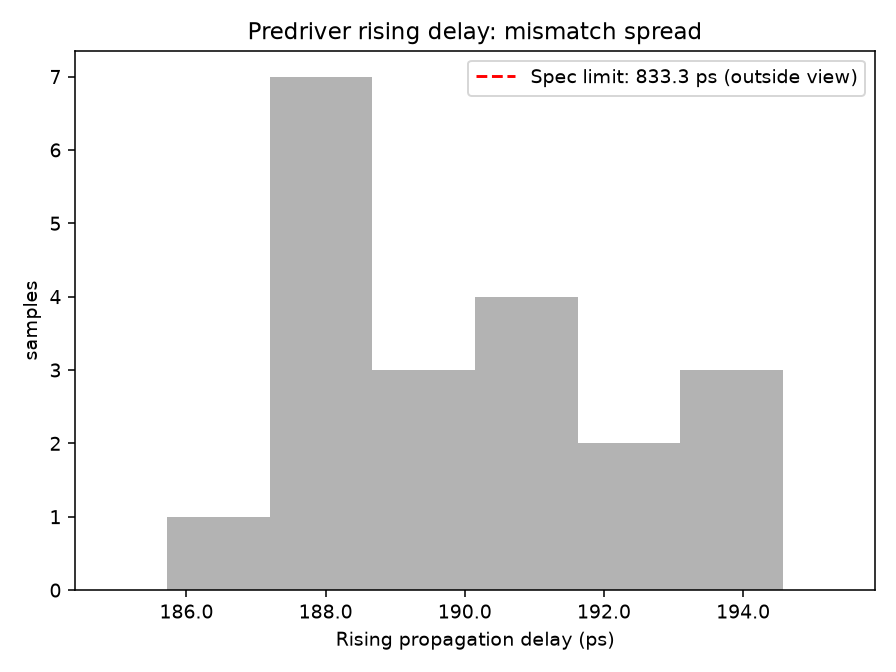

In [ ]:
# Jupyter: display the figure saved by the Silk analysis above.
if RUN_FULL_FLOW:
    display(Image(filename=str(REVIEW / "predriver_mismatch.png")))

## 9. Estimate area and parasitic loading

### 9.1 Estimate the circuit hierarchy

Silk includes `estimate_layout()` for early area and interconnect estimates. `RoutingModel.from_pdk()` supplies process routing data, and `children="estimate"` estimates child footprints before the parent. Footprints explicitly fixed with `set_footprint()` are preserved.

The demo's `estimate_hierarchy()` helper uses these APIs and `iter_instances()` to collect a table for the full transmitter. Child wire R/C needs a separate estimate for each block; the native footprint recursion alone does not calculate it.

Compare three packing and routing-overhead assumptions to see how sensitive the total area is. Routing overhead applies at each hierarchy level.

These are planning estimates, not a placed layout. MOS area starts from W × L × multiplier with a packing factor; ideal passives use placeholder footprints. Pads, ESD, package effects, and routed extraction are not included.

In [ ]:
from circuits.process import TECHNOLOGIES
from silk.layout import RoutingModel, estimate_layout, inject_parasitics
from characterization.physical import estimate_hierarchy
from copy import deepcopy

if RUN_FULL_FLOW:
    # Silk API: load routing data for this PDK.
    routing = RoutingModel.from_pdk(selected_dut.pdk_details)
    # Demo helper: collect native area and wire estimates for each block.
    areas = estimate_hierarchy(selected_dut,routing,packing_factor=2.5,routing_overhead=1.2)
    table([{"block":row["path"],"estimated area um2":round(row["area_um2"],2)}
           for row in areas if row["path"].count(".")<=1])
    sensitivities=[]
    for packing,overhead in ((2.0,1.1),(2.5,1.2),(3.0,1.3)):
        trial=deepcopy(selected_dut)
        # Silk API: estimate children first, then the complete transmitter.
        area=estimate_layout(trial,routing,children="estimate",packing_factor=packing,routing_overhead=overhead)
        sensitivities.append({"packing":packing,"routing overhead per level":overhead,"total um2":round(area.bounding_box[0]*area.bounding_box[1],2)})
    table(sensitivities)
    (REVIEW / "area.json").write_text(json.dumps({"routing":asdict(routing),"sensitivity":sensitivities,
        "child_footprints":areas[-1]["estimate"].child_footprints,
        "blocks":[{"path":row["path"],"area_um2":row["area_um2"]} for row in areas]},indent=2, default=asdict))

### 9.2 Simulate with estimated interconnect capacitance

Silk includes `inject_parasitics()` to add estimated loading to a circuit, then rerun the same tests and specifications. This example demonstrates that flow by adding shunt capacitors to **top-level transmitter signal nets only**, using `mode="c_only"` and `return_net="VSS"`. Supply nets are excluded, and the capacitors are added before placing the transmitter in its testbench. Internal wiring within the serializer, retiming cells and driver is not included.

**The two eyes look almost identical because the channel load dominates.** The added top-level capacitances are approximately **0.35–0.50 fF per net**, compared with the existing **2 pF (2,000 fF) channel capacitance per leg**. The external 50 Ω / 2 pF channel stays unchanged. At this loading level, the measured eye changes very little; this does not establish that internal wiring parasitics would also be negligible.

Compare eye opening, bit errors, power and device stress using the same link test. Then fit a separate behavioral model for the loaded circuit, keeping the nominal model unchanged. These are estimated capacitive loads, not extracted layout parasitics or a model of routed wire delay.


In [ ]:
if RUN_FULL_FLOW:
    # Demo helper: build a separate copy of the selected transmitter.
    loaded_dut=build_serdes_tx(variant=selected["variant"], cmos_predriver=selected["cmos_predriver"],
                               tech=TECHNOLOGIES[selected["process"]], eq_strength=selected["eq_strength"])
    loading_estimates=estimate_hierarchy(loaded_dut,routing,packing_factor=2.5,routing_overhead=1.2)
    estimate=loading_estimates[-1]["estimate"]
    signal_nets={name:value for name,value in estimate.nets.items() if name not in ("VDD","VSS","gnd","0")}
    # Silk API: add estimated signal-net capacitance before testbench placement.
    inject_parasitics(loaded_dut,replace(estimate,nets=signal_nets),
                      mode="c_only",return_net="VSS")
    injected_caps=sum(name.startswith("__par_C") for name in loaded_dut.passives_dict)
    loaded_dut,loaded_tb=build_characterization(selected,REVIEW / "estimated_loading",dut=loaded_dut)
    # Silk API: emit the deck and check that the added capacitors are present.
    loaded_deck=Path(loaded_tb.netlist.generate_netlist()).read_text()
    assert loaded_deck.count("C__par_C") == injected_caps > 0
    # Silk API: rerun the same link test, then check device stress.
    loaded_report=loaded_dut.run_test("link",corner="tt")
    print(loaded_report.summary())
    loaded_stress=check_junction_overrange(loaded_tb.netlist)
    table([{"case": label,
            "eye mV": report.metrics["link.eye_height_v"] * 1e3,
            "eye UI": report.metrics["link.eye_width_ui"],
            "bit errors": report.metrics["link.bit_errors"],
            "power mW": report.metrics["average_power_w"] * 1e3}
           for label, report in [("nominal", selected_report),
                                 ("estimated loading", loaded_report)]])
    print(f"Injected {injected_caps} capacitors on TX-level interconnect nets; stress findings: {len(loaded_stress)}")
    generate_report(loaded_tb.netlist,spec_reports=[loaded_report]).save_html(str(REVIEW/"estimated_loading_report.html"))
    # Silk API: probe the loaded receiver waveform.
    vp,vn=loaded_tb.probe("rxp"),loaded_tb.probe("rxn")
    # Demo helper: fit a separate response model for the loaded circuit.
    loaded_calibration=fit_response(vp.x,(vp - vn).y,selected)
    loaded_calibration.update(loading="estimated c_only; PDK routing data; packing 2.5; overhead 1.2",rawfile=loaded_report.rawfile_path)
    loaded_model=build_response_model(selected,REVIEW/"loaded_model")
    # Silk API: write fitted coefficients into the new behavioral model.
    for name,value in loaded_calibration["coefficients"].items():
        loaded_model.calibrate_behavioral(name,value)
    (REVIEW/"loaded_calibration.json").write_text(json.dumps(loaded_calibration,indent=2, default=asdict))
    result_rows.append({"case":"estimated loading",**{k: v for k, v in loaded_report.metrics.items() if k != "link"}})
    run_evidence.append({"case":"estimated loading","settings":dict(selected),"rawfile": loaded_report.rawfile_path, "parameters": loaded_report.parameters,
                         "loading":"c_only PDK estimates","stress_findings":len(loaded_stress)})

#### Compare schematic and estimated-loading eyes

The left eye is the selected schematic; the right adds the estimated transmitter-level capacitances. Both use the same channel, stimulus, tap setting, and voltage scale. Silk measures and centers each eye.

In [ ]:
from silk.metrics import eye_diagram
from tools.notebook_display import draw_eye  # Axis labels and trace formatting only.

if RUN_FULL_FLOW:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
    for ax, title, bench in [
        (axes[0], "Selected schematic", selected_tb),
        (axes[1], "With estimated capacitance", loaded_tb),
    ]:
        # Demo helper: use the same measurement window as the registered link test.
        measured = read_measurements(bench.netlist, selected)
        # Silk API: select the measured differential receiver waveform.
        rx = (bench.probe("rxp") - bench.probe("rxn")).window(
            measured["measurement_start_s"], measured["measurement_stop_s"])
        ui = 1 / selected["bit_rate_hz"]
        # Silk API: measure and center both eyes with identical settings.
        eye = eye_diagram(rx, period=ui, auto_center=True, threshold=0.0)
        draw_eye(ax, eye, ui, title)
    fig.tight_layout()
    fig.savefig(REVIEW / "estimated_loading_eyes.png", dpi=150)
    # Jupyter: embed the saved image, including on headless/GitHub renderers.
    display(Image(filename=str(REVIEW / "estimated_loading_eyes.png")))
    plt.close(fig)

## 10. Change architecture, reuse the tests

Silk's `run_test("link")` runs the complete registered link verification recipe: it builds the simulation deck, runs the simulator, evaluates every registered metric, and checks the results against the specifications. The returned report contains the measurements and pass/fail outcomes. With `store=True`, the result can also be saved in the design database.

Here, `variant="cml"` selects a different transmitter implementation through the demo factory. The same `run_test("link")` call reuses the PRBS checks, eye measurements, power measurement, and specifications. We do not write a second measurement or pass/fail flow for CML.

For a circuit with several registered tests, Silk's `run_all_tests()` runs the full test suite, including registered tests in child blocks by default. This example runs the named `link` test.

The factory supplies the CML circuit with differential 0.4 V data and clock swings, a wider LOAD pulse, and a diode-referenced 800 µA bias. CML uses its own resistive driver loads without the CMOS receiver's extra 100 Ω termination.

For CML, `eq_strength` scales auxiliary current-steering slice counts, with at least one slice. For CMOS, it scales resistor attenuation. The setting expresses the same design intent, but the analog weights and loads differ. This demonstrates reuse of the design flow, not a matched-load power comparison.

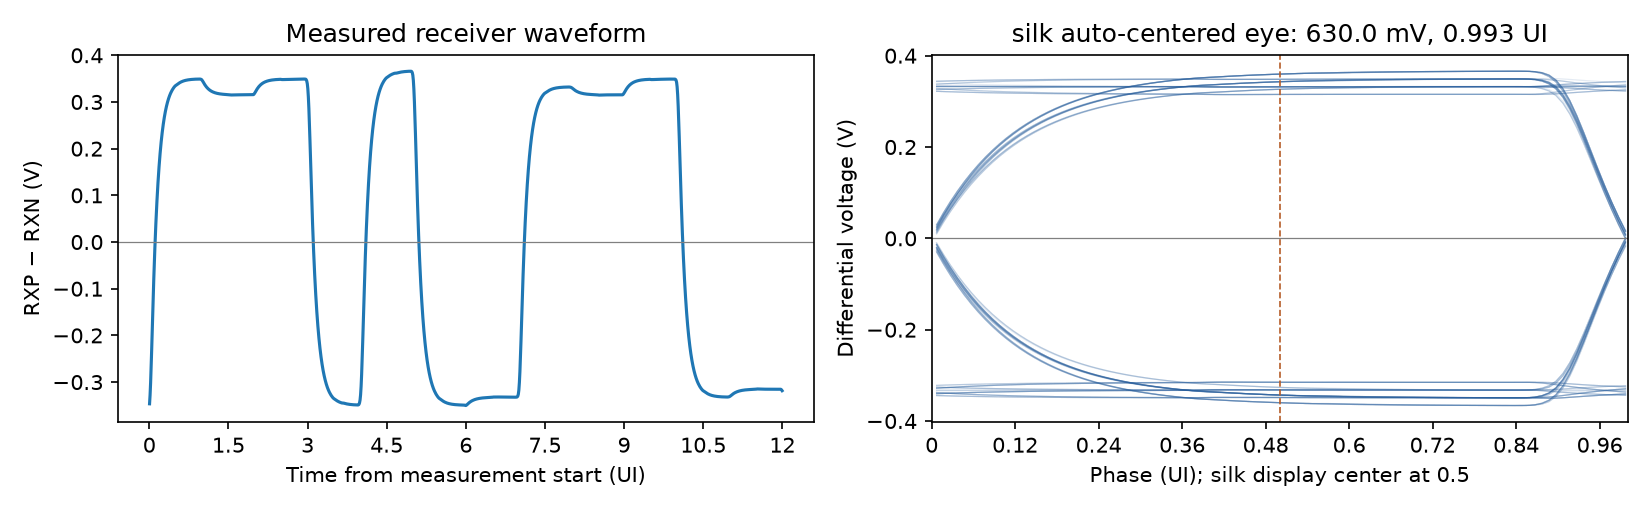

In [ ]:
if RUN_FULL_FLOW:
    # Demo setting: switch the circuit implementation to CML.
    cml_settings=dict(selected,variant="cml",prbs_offset=233)
    cml_dut,cml_tb=build_characterization(cml_settings,REVIEW/"cml")
    # Silk API: simulate the registered link test, evaluate all its metrics,
    # and check every specification. The returned report contains the results.
    cml_report=cml_dut.run_test("link",corner="tt")
    print(cml_report.summary())
    # Silk API: check device stress and available waveform coverage.
    cml_stress=check_junction_overrange(cml_tb.netlist)
    print("CML stress findings:",len(cml_stress),junction_stress_coverage(cml_tb.netlist).summary())
    # Silk API: load PDK routing data; the demo helper collects block estimates.
    cml_routing=RoutingModel.from_pdk(cml_dut.pdk_details)
    cml_areas=estimate_hierarchy(cml_dut,cml_routing)
    print("CML estimated area:",cml_areas[-1]["area_um2"],"um² (same estimation assumptions)")
    (REVIEW/"cml_area.json").write_text(json.dumps({"routing":asdict(cml_routing),
        "packing_factor":2.5,"routing_overhead":1.2,
        "blocks":[{"path":row["path"],"area_um2":row["area_um2"]} for row in cml_areas]},indent=2, default=asdict))
    # Silk API: save the circuit and rule-coverage reports.
    cml_native=generate_report(cml_tb.netlist,spec_reports=[cml_report])
    cml_native.save_json(str(REVIEW/"cml_report.json"))
    cml_native.save_html(str(REVIEW/"cml_report.html"))
    cml_native.coverage.save_json(str(REVIEW/"cml_rule_coverage.json"))
    # Demo helper: draw the receiver waveform and native Silk eye result.
    save_figures(cml_tb.netlist,cml_settings,read_measurements(cml_tb.netlist,cml_settings),REVIEW/"cml")
    display(Image(filename=str(REVIEW/"cml"/"waveform_eye.png")))
    result_rows.append({"case":"CML same tests",**{k: v for k, v in cml_report.metrics.items() if k != "link"}})
    run_evidence.append({"case":"CML same tests","settings":dict(cml_settings),"rawfile": cml_report.rawfile_path, "parameters": cml_report.parameters,
                         "stress_findings":len(cml_stress)})

## 11. Port the hierarchy to another process

Silk includes `load_pdk()` and PDK device factories to build circuits in different processes. This demo's `Technology` settings choose the device factories, starting dimensions, supply, and corner. Every block uses that same mapping, so it applies throughout the serializer, retiming, and driver hierarchy.

| Setting | sky130 | GF180 |
|---|---|---|
| PDK | `load_pdk("sky130")` | `load_pdk("gf180mcu")` |
| MOS factories | `nmos1p8` / `pmos1p8` | `nmos3p3` / `pmos3p3` |
| Width and length scale | 1× | 2× |
| Unit inverter NMOS W/L | 1.0 / 0.15 µm | 2.0 / 0.30 µm |
| Unit inverter PMOS W/L | 2.0 / 0.15 µm | 4.0 / 0.30 µm |
| Supply / corner | 1.8 V / `tt` | 3.3 V / `typical` |

This is an explicit starting-point port, not automatic performance matching. Connections, multipliers, passive values, selected equalizer setting, bit rate, and tests are reused. The 2× dimensions are an assumption; drive strength, delay, and power have not been matched or reoptimized. CML on GF180 is not supported by this demo.

GF180 is a preview integration in Silk 0.2.0. Its catalog has no sourced routing data, so area estimation is reported as unavailable rather than using sky130 assumptions.

### 11.1 Inspect the device mapping

Print a unit inverter from each process to check the actual model names and dimensions in the emitted netlists.

In [ ]:
from circuits.process import GF180, SKY130
from circuits.stdcells import build_inverter

if RUN_FULL_FLOW:
    for tech in (SKY130, GF180):
        print(f"{tech.name}: actual mapped unit inverter")
        # Demo factory selects devices; Silk generate_netlist() emits SPICE.
        inverter = build_inverter(tech=tech)
        print(inverter.generate_netlist())
    table([{"process":t.name,"NMOS":t.nmos,"PMOS":t.pmos,"VDD":t.nominal_v,
            "width scale":t.width_scale,"length scale":t.length_scale,"corner":t.corner} for t in (SKY130,GF180)])

### 11.2 Run the ported transistor circuit

Reuse the link test at 3.3 V and the GF180 `typical` corner.

In [ ]:
if RUN_FULL_FLOW:
    port_settings=dict(selected,process="gf180mcu",supply_v=3.3,prbs_offset=0)
    port_dut,port_tb=build_characterization(port_settings,REVIEW/"gf180_training")
    # Silk API: run the existing link test at the GF180 corner.
    port_report=port_dut.run_test("link",corner=GF180.corner)
    print(port_report.summary())

### 11.3 Calibrate the GF180 model

Silk's `calibrate_behavioral()` applies fitted values to model parameters. Fit fresh coefficients from the GF180 run, then compare the fixed model with another SPICE run using a shifted PRBS9 segment. Sky130 coefficients are not reused; the shifted segment is still part of the same PRBS9 sequence.

In [ ]:
if RUN_FULL_FLOW:
    # Silk API: read the GF180 receiver waveform.
    vp,vn=port_tb.probe("rxp"),port_tb.probe("rxn")
    # Demo helper: fit new coefficients from GF180 SPICE results.
    port_fit=fit_response(vp.x,(vp - vn).y,port_settings)
    port_fit["rawfile"]=port_report.rawfile_path
    port_model=build_response_model(port_settings,REVIEW/"gf180_model")
    # Silk API: apply the fitted coefficients to a separate GF180 model.
    for name,value in port_fit["coefficients"].items():
        port_model.calibrate_behavioral(name,value)
    port_validation_settings=dict(port_settings,prbs_offset=233)
    port_val_dut,port_val_tb=build_characterization(port_validation_settings,REVIEW/"gf180_validation")
    # Silk API: rerun the transistor test with a shifted PRBS segment.
    port_val_report=port_val_dut.run_test("link",corner=GF180.corner)
    port_behavioral=build_behavioral_bench(port_model,port_validation_settings,REVIEW/"gf180_behavioral")
    ui=1/port_settings["bit_rate_hz"]
    # Silk API: probe and run the behavioral test without a SPICE simulator.
    prediction=port_behavioral.probe("dout")
    port_behavioral_report=port_behavioral.run()
    print(port_behavioral_report.summary())
    port_behavioral_report.save_json(REVIEW / "gf180_behavioral_spec_report.json")
    vp,vn=port_val_tb.probe("rxp"),port_val_tb.probe("rxn")
    port_residual=validation_residual(prediction.x,prediction.y,vp.x,(vp - vn).y,port_validation_settings)

### 11.4 Check stress and save the port results

Reuse Silk's device-stress and reporting APIs. Report missing GF180 routing data explicitly, so the area estimate is not mistaken for a verified result.

In [ ]:
if RUN_FULL_FLOW:
    # Silk API: check the GF180 devices against their own catalog limits.
    port_stress=check_junction_overrange(port_val_tb.netlist)
    try:
        # Silk API: request this process's routing data.
        port_routing=RoutingModel.from_pdk(port_dut.pdk_details)
    except ValueError as error:
        # A preview catalog may lack sourced routing data. Expose the gap;
        # do not replace it with another process's metal assumptions.
        if "declares no 'routing' section" not in str(error):
            raise
        port_area_evidence={"available":False,"reason":str(error)}
    else:
        port_areas=estimate_hierarchy(port_dut,port_routing)
        port_area_evidence={"available":True,"routing":asdict(port_routing),
            "packing_factor":2.5,"routing_overhead":1.2,
            "blocks":[{"path":row["path"],"area_um2":row["area_um2"]} for row in port_areas]}
    (REVIEW/"gf180_area.json").write_text(json.dumps(port_area_evidence,indent=2, default=asdict))
    print("Port validation:",port_val_report.summary())
    print("Model waveform error:",port_residual)
    print("Stress findings:",len(port_stress),junction_stress_coverage(port_val_tb.netlist).summary())
    print("Port area evidence:",port_area_evidence)
    # Silk API: save the ported circuit's performance and stress report.
    port_native=generate_report(port_val_tb.netlist,spec_reports=[port_val_report])
    port_native.save_html(str(REVIEW/"gf180_report.html"))
    port_native.save_json(str(REVIEW/"gf180_report.json"))
    port_native.coverage.save_json(str(REVIEW/"gf180_rule_coverage.json"))
    (REVIEW/"gf180_calibration.json").write_text(json.dumps({"fit":port_fit,"validation_residual":port_residual},indent=2, default=asdict))
    result_rows.append({"case":"GF180 CMOS validation",**{k: v for k, v in port_val_report.metrics.items() if k != "link"}})
    run_evidence.append({"case":"GF180 CMOS validation","settings":dict(port_validation_settings),
                         "rawfile": port_val_report.rawfile_path, "parameters": port_val_report.parameters,"stress_findings":len(port_stress)})

## 12. Save and revisit the design

Silk's database captures design information throughout the flow: circuit hierarchy and versions, specification targets and ownership, measured results, operating conditions, and run provenance. Earlier sections used `create_circuit_version()`, `run_test(store=True)`, and `store_report()` to record the baseline, selected design, and PVT results as they were produced.

Now rebuild the selected circuit and read those results back **without running a simulator**. `query_results()` finds saved measurements; `restore_spec_measurements()` restores them to the circuit's specifications. Select the nominal test profile explicitly so it is not confused with the nominal point in the PVT sweep.

The link targets belong to the transmitter module, while its registered testbench supplies the measurements. The additional table below uses `get_stored_specs()` to inspect those saved declarations from the parent circuit; `$` identifies the root transmitter. This is distinct from the baseline-to-selected version lineage.

Silk can also store annotated net-current sets with `store_net_currents()` and restore them for layout work. `annotate_currents()` produces average, RMS, and peak current information used for EM-related wire sizing. That requires device-current capture to be enabled before simulation. This demo records supply power, but has not captured those terminal-current sets; its area and capacitance estimates are geometric.

The database records which circuit version and conditions produced each measurement. Python still defines the circuit; raw waveforms and the calibrated model are separate artifacts. A parent version records design history, not permission to reuse its measurements on a changed circuit.

### 12.1 Restore the selected design's nominal results

In [ ]:
from silk.db import Database

lifecycle_evidence = None
if RUN_FULL_FLOW:
    # Silk API: close the tracked modules before reopening the saved design.
    for tracked_dut, tracked_tb, _, _ in characterization_runs:
        tracked_dut.close()
        tracked_tb.netlist.close()
    selected_dut.close()
    selected_tb.netlist.close()
    # Demo helper: rebuild the selected circuit without running its test.
    rebuilt_dut, rebuilt_tb = build_characterization(
        selected, REVIEW / "rebuilt_selected", db_path=DATABASE_PATH)
    # Silk API: resolve the same saved circuit version.
    restored_version = rebuilt_dut.create_circuit_version(parent_version_id=baseline_version)
    assert restored_version == selected_version
    # Silk API: find the nominal test profile, excluding the PVT sweep profile.
    nominal_rows = rebuilt_dut.query_results(parameter="link.eye_height_v", source="spice",
        corner="tt", temperature=selected["temperature_c"], voltage=selected["supply_v"],
        latest_only=True, include_ancestors=False)
    nominal_profiles = {row.profile_id for row in nominal_rows
                        if "silk_run_variables" not in (row.conditions or {})}
    assert len(nominal_profiles) == 1
    nominal_profile = nominal_profiles.pop()
    saved_eye = rebuilt_dut.query_results(parameter="link.eye_height_v", source="spice",
        corner="tt", temperature=selected["temperature_c"], voltage=selected["supply_v"],
        latest_only=True, include_ancestors=False, profile_id=nominal_profile)
    assert saved_eye and all(r.origin_version_id == selected_version for r in saved_eye)
    # Silk API: restore saved measurements and evaluate the specifications.
    restored_count = rebuilt_dut.restore_spec_measurements(source="spice", corner="tt",
        temperature=selected["temperature_c"], voltage=selected["supply_v"], include_ancestors=False, profile_id=nominal_profile)
    print("Resolved the same selected version:", restored_version)
    print("Restored specification measurements:", restored_count)
    assert restored_count > 0
    restored_specs = rebuilt_dut.reconcile_specs()
    stored_metrics = rebuilt_dut.query_results(source="spice", corner="tt",
        temperature=selected["temperature_c"], voltage=selected["supply_v"],
        latest_only=True, include_ancestors=False, profile_id=nominal_profile)
    expected_values = {row.parameter: row.value for row in stored_metrics}
    spec_rows = []
    for outcome in restored_specs.outcomes:
        measurement = outcome.measurement
        assert measurement is not None
        assert measurement.value == expected_values[outcome.spec.metric]
        assert (measurement.corner, measurement.temperature, measurement.voltage) == (
            "tt", selected["temperature_c"], selected["supply_v"])
        assert measurement.origin_version_id == selected_version
        spec_rows.append({"spec": outcome.spec.name, "operator": outcome.spec.op,
            "target": outcome.spec.target, "restored value": measurement.value,
            "status": outcome.status, "origin version": measurement.origin_version_id})
    table(spec_rows)

In [ ]:
# Silk API: inspect the transmitter's saved specification targets and ownership.
if RUN_FULL_FLOW:
    stored_specs = rebuilt_dut.get_stored_specs(
        include_measurements=False, include_ancestors=False)
    table([{"owner": spec.owner_path, "specification": spec.name,
            "metric": spec.metric, "condition": spec.op, "target": spec.target}
           for spec in stored_specs])

### 12.2 Read back the PVT sweep

Silk stores each report's operating conditions and captured Variable values. Read the eye measurements back for every saved point, even though the live supply Variable has returned to 1.8 V. This retrieves results; it does not rerun the sweep.

In [ ]:
if RUN_FULL_FLOW:
    # Silk API: query saved PVT results with their original operating conditions.
    pvt_saved = rebuilt_dut.query_results(parameter="link.eye_height_v", source="spice",
        latest_only=True, include_ancestors=False)
    pvt_saved = [row for row in pvt_saved if "silk_run_variables" in (row.conditions or {})]
    pvt_saved_status = rebuilt_dut.query_results(parameter="spec_eye_height_v", source="spice",
        latest_only=True, include_ancestors=False)
    pvt_saved_status = [row for row in pvt_saved_status
                        if "silk_run_variables" in (row.conditions or {})]
    if process_evidence is not None:
        assert len(pvt_saved_status) == len(process_evidence["rawfiles"])
    assert all(row.origin_version_id == selected_version and
               row.conditions["silk_run_variables"]["link_vdd"] == row.voltage
               for row in pvt_saved_status)
    print("Stored PVT points:", len(pvt_saved_status),
          "with numeric eye measurements:", len(pvt_saved),
          "(unavailable metrics keep their specification status)")
    table([{"corner": row.corner, "temperature C": row.temperature,
            "supply V": row.voltage, **row.conditions["silk_run_variables"],
            "eye mV": row.value * 1e3} for row in pvt_saved])

### 12.3 Inspect the design history

Silk's `Database` API can read saved measurements and version lineage directly. Confirm that the selected design follows the baseline, then save a summary of the restored evidence. The SQLite file is linked below; full measurement history is also saved in `design_history.json`.

In [ ]:
if RUN_FULL_FLOW:
    rebuilt_dut.close()
    rebuilt_tb.netlist.close()
    # Silk API: inspect version history directly, without rebuilding a circuit.
    with Database(DATABASE_PATH) as database:
        lineage = database.iter_version_lineage(selected_version)
        assert lineage == [selected_version, baseline_version]
        history_rows = []
        for label, version_id in (("baseline", baseline_version), ("selected", selected_version)):
            for metric, unit, scale in (("link.eye_height_v", "mV", 1e3),
                                        ("average_power_w", "mW", 1e3)):
                rows = database.get_simulation_results(version_id, parameter=metric,
                                                       include_ancestors=False)
                history_rows.extend({"design": label, "metric": metric, "corner": row.corner,
                    "temperature C": row.temperature, "supply V": row.voltage,
                    "value": row.value*scale, "unit": unit, "origin version": row.origin_version_id}
                    for row in rows)
    print(f"Saved history: {len(history_rows)} measurements across the baseline and selected designs.")
    lifecycle_evidence = {"database": DATABASE_PATH, "baseline_version": baseline_version,
        "selected_version": selected_version, "lineage": lineage,
        "restored_spec_measurements": restored_count, "history": history_rows, "restored_specs": spec_rows,
        "rebuild_required_simulation": False, "restored_pvt_points": len(pvt_saved_status), "numeric_pvt_eye_results": len(pvt_saved)}
    (REVIEW / "design_history.json").write_text(json.dumps(lifecycle_evidence, indent=2))
    show_file(Path(DATABASE_PATH).relative_to(DEMO_ROOT))
else:
    print("No measured design history created in structural-only mode.")


## 13. From circuit specifications to verified results

**In Silk, the circuit definition, its tests and its specifications form a reusable design that can be simulated, refined and verified through the same workflow.** The designer defines the circuit and what it must achieve in Python. Silk provides a common workflow to simulate it, measure its performance, check specifications, explore changes and preserve the evidence behind each design decision.

This transmitter demonstrates that connection across the design cycle:

- **Turn specifications into a design improvement.** The baseline eye height is below the target. The optimizer uses the registered link measurement to choose an equalizer setting, and the same test checks the improved design. Eye height, bit errors, power and energy per bit remain available for comparison.
- **Reuse verification as the implementation changes.** The link test and its targets carry through PVT sweeps, estimated parasitic loading and the CMOS/CML comparison. The GF180 example reuses the circuit-building approach and verification with explicit process device and sizing choices; GF180 remains a preview integration.
- **Connect transistor accuracy with behavioral speed.** SPICE measurements calibrate the behavioral model. The notebook then compares that model with transistor simulation over a full PRBS9 period and additional operating conditions, making its fidelity visible.
- **Bring physical effects and device limits into the loop.** The circuit hierarchy supplies area and parasitic-capacitance estimates. We add that capacitance to the circuit and rerun the same link test against the original specifications, connecting physical estimates to electrical performance. Specifications and characterization results stay associated with the design as it progresses toward layout, preserving information from earlier stages. Separate device-stress checks show why a passing link specification alone does not establish that every transistor stays within its voltage limits. These are early design checks, not a completed physical layout.
- **Keep a design history that can be revisited.** The database records circuit versions, specifications and measured results with their operating conditions. The notebook closes and rebuilds the design, then retrieves the stored evidence without repeating the simulations.

**Silk lets designers change a circuit while keeping its verification and design history connected.** A change to an architecture, design parameter or process can be evaluated through the same measurement and reporting workflow. Because that workflow is Python, designers can inspect it, version it, extend it and automate repeated decisions. The same explicit APIs also make the flow accessible to scripts and AI agents, with the circuit specifications providing the criteria for judging their changes.

The APIs below are the building blocks used in this walkthrough.

| Design step demonstrated | Key Silk APIs |
|---|---|
| Build and inspect the hierarchy | `Module`, `define_module_ports()`, `add_module()`, `module_graph()` |
| Select process devices | `load_pdk()` and PDK device factories |
| Generate known data | `prbs_bits()`, `PRBS`, `sources.voltage.bitpattern()` |
| Define reusable verification | `create_test()`, `add_metric()`, `add_spec()` |
| Simulate, measure, and check specifications | `run_test()`, `probe()`, `sample()`, `eye_diagram()`, `average_power()` |
| Select equalizer settings | `Variable`, `VariableSpace`, `Optimizer.sweep()` |
| Check operating conditions and mismatch | `set_corners()`, `set_temperatures()`, `set_variable_values()`, `set_groups()`, `run_monte_carlo()` |
| Calibrate and run a behavioral model | `set_behavioral_model()`, `Measurement`, `CalibrationBinding`, `reconcile_specs()` |
| Check device stress | `check_junction_overrange()`, `junction_stress_coverage()` |
| Estimate physical effects | `RoutingModel.from_pdk()`, `estimate_layout()`, `inject_parasitics()` |
| Preserve and revisit design evidence | `create_circuit_version()`, `store_report()`, `get_stored_specs()`, `query_results()`, `restore_spec_measurements()` |
| Share the results | `generate_report()`, `save_html()`, `save_json()`, `emit_view()` |

The measured comparison below brings the flow together: eye opening, observed bit errors, power, and energy per bit for each design case. The linked reports retain the conditions and specification outcomes behind those numbers.

To reproduce the walkthrough, run section 1's setup and then the cells in order with `RUN_SPICE = True` and `VARIANT = "cmos"`. Each execution keeps its reports, plots, waveforms, and software/model versions in its own results folder.

In [ ]:
if RUN_FULL_FLOW:
    # Demo presentation: compare measurements from the Silk reports.
    table([{"case":row["case"],"errors":row["link.bit_errors"],"eye mV":round(row["link.eye_height_v"]*1e3,2),
            "eye UI":round(row["link.eye_width_ui"],2),"power mW":round(row["average_power_w"]*1e3,3),
            "energy pJ/bit":round(row["energy_per_bit_j"]*1e12,3)} for row in result_rows])
    # Save the combined results and links to the supporting evidence.
    summary={"results":result_rows,"runs":run_evidence,"source_environment":provenance,
             "pvt":process_evidence,"predriver_monte_carlo":mc_evidence,
             "design_history":lifecycle_evidence,"selected_settings":dict(selected),"behavioral_validation":residual,
             "remaining_limitations":["CMOS internal overshoot findings","GF180 preview support; missing sourced routing data prevents port area/loading estimates",
                 "estimated geometry/loading only","no independent loaded-model validation",
                 "short deterministic records are not a BER guarantee; the tested grid is not an exhaustive operating envelope"]}
    (REVIEW/"summary.json").write_text(json.dumps(summary,indent=2, default=asdict))
    (ARTIFACTS/"latest_review.json").write_text(json.dumps({"folder":str(REVIEW.relative_to(DEMO_ROOT))},indent=2, default=asdict))
    # Jupyter: show links to the saved summary and waveform viewer.
    print("Results folder:", REVIEW)
    show_file((REVIEW/"summary.json").relative_to(DEMO_ROOT))
    show_file((REVIEW/"baseline_waveforms.html").relative_to(DEMO_ROOT))
else:
    print("Structural walkthrough finished. Set RUN_SPICE=True with VARIANT='cmos' to execute the full flow.")

## References

**Software and process models**

1. [Silk (`circuitsilk` 0.2.0)](https://github.com/levantlabs/silk), MIT license; [PyPI package](https://pypi.org/project/circuitsilk/).
2. [ngspice circuit simulator](https://ngspice.sourceforge.io/).
3. [SkyWater SKY130 open-source PDK](https://github.com/google/skywater-pdk).
4. [GlobalFoundries GF180MCU open-source PDK](https://github.com/google/gf180mcu-pdk).
5. [open_pdks](https://github.com/RTimothyEdwards/open_pdks), which builds the PDK model libraries.
6. [Volare 0.20.6](https://pypi.org/project/volare/0.20.6/), PDK version manager.
7. [pdksetup](https://github.com/levantlabs/pdksetup), the PDK installer used by the setup cell.
8. [NumPy](https://numpy.org/), [Matplotlib](https://matplotlib.org/), and [Jupyter](https://jupyter.org/).

**Reused code**

9. The circuit cells and testbench helpers are adapted from Silk's own examples, listed file by file in [source_provenance.json](source_provenance.json). No other notebooks were reused.